In [1]:
import joblib
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold

In [2]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

In [3]:
import os
import numpy as np
import pandas as pd

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
processed_dir = "../data/processed"

In [6]:
X_train = pd.read_csv(os.path.join(processed_dir, "X_train_new.csv"))
X_test = pd.read_csv(os.path.join(processed_dir, "X_test_new.csv"))
y_train = pd.read_csv(os.path.join(processed_dir, "y_train_new.csv")).squeeze("columns")
y_test = pd.read_csv(os.path.join(processed_dir, "y_test_new.csv")).squeeze("columns")

In [7]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (534932, 19)
X_test shape:  (133733, 19)
y_train shape: (534932,)
y_test shape:  (133733,)


In [8]:
X = pd.concat([X_train, X_test], ignore_index=True)
y = pd.concat([y_train, y_test], ignore_index=True)

print(" X :", X.shape)
print(" y :", y.shape)

 X : (668665, 19)
 y : (668665,)


In [9]:
from imblearn.over_sampling import SMOTE

In [10]:
X1 = X.copy()
y1 = y.copy()

In [11]:
y1.value_counts()

Will_Buy_EV
0    551886
1    116779
Name: count, dtype: int64

In [12]:
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X1, y1)

In [13]:
print(pd.Series(y_resampled).value_counts())

Will_Buy_EV
0    551886
1    551886
Name: count, dtype: int64


In [14]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import GridSearchCV

In [15]:
X2 = X.copy()
y2 = y.copy()

In [16]:
rus = RandomUnderSampler(random_state=42)
X_resampled1, y_resampled1 = rus.fit_resample(X2, y2)

In [17]:
print(pd.Series(y_resampled1).value_counts())

Will_Buy_EV
0    116779
1    116779
Name: count, dtype: int64


In [19]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42,)

In [27]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}

fold_aucs = []
fold_accuracies = []
all_y_true = []
all_y_pred = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X2, y2)):
    print(f"\n--- Training Fold {fold + 1} ---")
    
    X_tr, X_val = X2.iloc[train_idx], X2.iloc[val_idx]
    y_tr, y_val = y2.iloc[train_idx], y2.iloc[val_idx]
    
    base_model = XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    )
    
    grid_search = GridSearchCV(
        estimator=base_model,
        param_grid=param_grid,
        scoring='roc_auc',  
        cv=3,             
        n_jobs=-1
    )
    
    grid_search.fit(X_tr, y_tr)
    
    best_model = grid_search.best_estimator_
    print(f"Best Params for Fold {fold + 1}: {grid_search.best_params_}")
    
    preds = best_model.predict(X_val)
    probs = best_model.predict_proba(X_val)[:, 1]
    
    acc = accuracy_score(y_val, preds)
    auc = roc_auc_score(y_val, probs)
    
    fold_accuracies.append(acc)
    fold_aucs.append(auc)
    
    all_y_true.extend(y_val)
    all_y_pred.extend(preds)
    
    print(f"Fold {fold + 1} Accuracy: {acc:.4f} | ROC-AUC: {auc:.4f}")

print("\n================================")
print(f"Mean Accuracy across 5 Folds: {np.mean(fold_accuracies):.4f}")
print(f"Mean ROC-AUC across 5 Folds:  {np.mean(fold_aucs):.4f}")
print("================================")

print("\n--- Overall Classification Report (Out-of-Fold) ---")
print(classification_report(all_y_true, all_y_pred, digits=4))


--- Training Fold 1 ---
Best Params for Fold 1: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}
Fold 1 Accuracy: 0.8976 | ROC-AUC: 0.9417

--- Training Fold 2 ---
Best Params for Fold 2: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}
Fold 2 Accuracy: 0.8990 | ROC-AUC: 0.9420

--- Training Fold 3 ---
Best Params for Fold 3: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}
Fold 3 Accuracy: 0.8979 | ROC-AUC: 0.9411

--- Training Fold 4 ---
Best Params for Fold 4: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}
Fold 4 Accuracy: 0.8984 | ROC-AUC: 0.9413

--- Training Fold 5 ---
Best Params for Fold 5: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 200}
Fold 5 Accuracy: 0.8979 | ROC-AUC: 0.9421

Mean Accuracy across 5 Folds: 0.8981
Mean ROC-AUC across 5 Folds:  0.9417

--- Overall Classification Report (Out-of-Fold) ---
              precision    recall  f1-score   support

           0     0.9308    0.9470    0.9388    441509
        

In [25]:
print("--- Evaluating XGBoost on Test Data ---")

test_preds = model.predict(X_test)
test_probs = model.predict_proba(X_test)[:, 1]

test_acc = accuracy_score(y_test, test_preds)
test_auc = roc_auc_score(y_test, test_probs)

print(f"Test Accuracy: {test_acc:.4f} | Test ROC-AUC: {test_auc:.4f}")

print("\n--- Test Set Classification Report ---")
print(classification_report(y_test, test_preds, digits=4))

--- Evaluating XGBoost on Test Data ---
Test Accuracy: 0.8978 | Test ROC-AUC: 0.9409

--- Test Set Classification Report ---
              precision    recall  f1-score   support

           0     0.9302    0.9472    0.9386    110377
           1     0.7269    0.6640    0.6940     23356

    accuracy                         0.8978    133733
   macro avg     0.8285    0.8056    0.8163    133733
weighted avg     0.8947    0.8978    0.8959    133733



In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [16]:
cm = confusion_matrix(all_y_true, all_y_pred)

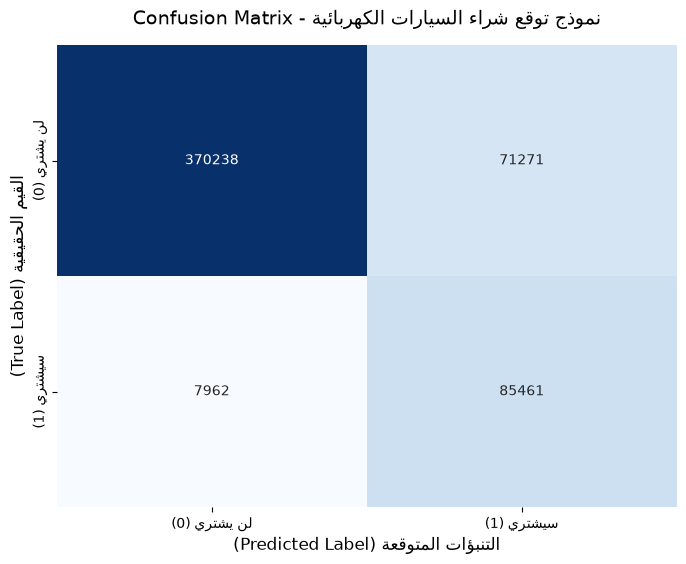

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['لن يشتري (0)', 'سيشتري (1)'],
            yticklabels=['لن يشتري (0)', 'سيشتري (1)'])

plt.xlabel('التنبؤات المتوقعة (Predicted Label)', fontsize=12)
plt.ylabel('القيم الحقيقية (True Label)', fontsize=12)
plt.title('Confusion Matrix - نموذج توقع شراء السيارات الكهربائية', fontsize=14, pad=15)
plt.show()

In [13]:
model_filename = 'ev_xgb_model.pkl'

In [14]:
joblib.dump(model, model_filename)

['ev_xgb_model.pkl']

In [ ]:
############################################################################

In [18]:
best_params = {
    'learning_rate': 0.2,
    'max_depth': 3,
    'n_estimators': 200,
    'random_state': 42,
    'n_jobs': -1,
    'eval_metric': 'logloss'
}

In [19]:
final_model = XGBClassifier(**best_params)

In [20]:
final_model.fit(X1, y1)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [26]:
test_df = pd.read_csv("test.csv")

test_ids = test_df['id']
X_test = test_df.drop(columns=['id']).copy()

anxiety_map = {'Low': 0, 'Medium': 1, 'High': 2}

X_test['Total_Charging_Stations'] = X_test['Charging_Stations_Near_Home'] + X_test['Charging_Stations_Near_Work']
X_test['Has_Any_Charging_Access'] = ((X_test['Total_Charging_Stations'] > 0) | (X_test['Home_Charging_Possible'] == 'Yes')).astype(int)
X_test['Commute_Anxiety_Interaction'] = X_test['Daily_Commute_km'] * (X_test['Range_Anxiety_Level'].map(anxiety_map) + 1)
X_test['Income_Per_Car'] = X_test['Annual_Income_USD'] / (X_test['Number_of_Cars_Owned'] + 1)

X_test['Home_Charging_Possible'] = X_test['Home_Charging_Possible'].map({'Yes': 1, 'No': 0})
X_test['Range_Anxiety_Level'] = X_test['Range_Anxiety_Level'].map(anxiety_map)
X_test['Subsidy_Available'] = X_test['Subsidy_Available'].map({'Yes': 1, 'No': 0})

cols_to_encode = ['Gender', 'City_Type', 'Current_Car_Type']
X_test = pd.get_dummies(X_test, columns=cols_to_encode)

continuous_cols = [
    'Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned',
    'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work',
    'Environmental_Concern_Level', 'Total_Charging_Stations',
    'Commute_Anxiety_Interaction', 'Income_Per_Car'
]

if 'scaler' in globals():
    X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

X_test.drop(columns=['Total_Charging_Stations', 'Income_Per_Car'], inplace=True, errors='ignore')

X_test = X_test.reindex(columns=X2.columns, fill_value=0)

y_test_probs = final_model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    'id': test_ids,
    'Will_Buy_EV': y_test_probs
})

submission.to_csv('submission.csv', index=False)

print("submission.csv!")
print(submission.head())

submission.csv!
       id  Will_Buy_EV
0  668665     0.179189
1  668666     0.126670
2  668667     0.133275
3  668668     0.184438
4  668669     0.850221


######################################################################################################

In [1]:
from classification_model import Perceptron, AdalineGD, LogisticRegressionGD, NeuralNetwork

In [2]:
import os
import numpy as np
import pandas as pd

In [3]:
processed_dir = "../data/processed"

In [4]:
X_train = pd.read_csv(os.path.join(processed_dir, "X_train_new.csv"))
X_test = pd.read_csv(os.path.join(processed_dir, "X_test_new.csv"))
y_train = pd.read_csv(os.path.join(processed_dir, "y_train_new.csv")).squeeze("columns")
y_test = pd.read_csv(os.path.join(processed_dir, "y_test_new.csv")).squeeze("columns")


print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

X_train shape: (534932, 19)
X_test shape:  (133733, 19)
y_train shape: (534932,)
y_test shape:  (133733,)


In [6]:
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

X_train_np = np.array(X_train)
y_train_np = np.array(y_train)
X_test_np = np.array(X_test)
y_test_np = np.array(y_test)

num_features = X_train_np.shape[1]


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_np = np.array(y_train)
y_test_np = np.array(y_test)

num_features = X_train_scaled.shape[1]

In [7]:
# ==========================================
# 1. Perceptron
# ==========================================
print("=== 1. Perceptron ===")
perceptron = Perceptron(num_features=num_features, learning_rate=0.001, epochs=50)
perceptron.fit(X_train_scaled, y_train_np)

y_pred_perc = np.array([perceptron.predict(x) for x in X_test_scaled])
print(f"Perceptron Accuracy: {np.mean(y_pred_perc == y_test_np) * 100:.2f}%")
print(classification_report(y_test_np, y_pred_perc))
print("=" * 60 + "\n")


=== 1. Perceptron ===
Epoch 1/50 - عدد الأخطاء: 77355
Epoch 10/50 - عدد الأخطاء: 78549
Epoch 20/50 - عدد الأخطاء: 78292
Epoch 30/50 - عدد الأخطاء: 78466
Epoch 40/50 - عدد الأخطاء: 78556
Epoch 50/50 - عدد الأخطاء: 78711
Perceptron Accuracy: 86.46%
              precision    recall  f1-score   support

           0       0.90      0.94      0.92    110377
           1       0.65      0.49      0.56     23356

    accuracy                           0.86    133733
   macro avg       0.77      0.72      0.74    133733
weighted avg       0.85      0.86      0.86    133733




In [16]:
# ==========================================
# 2. Adaline GD (معدل تعلم صغير جداً لمنع الانفجار)
# ==========================================
print("=== 2. Adaline GD ===")
adaline = AdalineGD(num_features=num_features, learning_rate=1e-19, epochs=50)
adaline.fit(X_train_scaled, y_train_np)

y_pred_ada = np.array([adaline.predict(x) for x in X_test_scaled])
print(f"Adaline Accuracy: {np.mean(y_pred_ada == y_test_np) * 100:.2f}%")
print(classification_report(y_test_np, y_pred_ada))
print("=" * 60 + "\n")


=== 2. Adaline GD ===
Epoch 1/50 - Cost: 1727492.7323
Epoch 10/50 - Cost: 1727492.7323
Epoch 20/50 - Cost: 1727492.7323
Epoch 30/50 - Cost: 1727492.7323
Epoch 40/50 - Cost: 1727492.7323
Epoch 50/50 - Cost: 1727492.7322
Adaline Accuracy: 59.40%
              precision    recall  f1-score   support

           0       0.86      0.61      0.71    110377
           1       0.22      0.53      0.31     23356

    accuracy                           0.59    133733
   macro avg       0.54      0.57      0.51    133733
weighted avg       0.75      0.59      0.64    133733




In [21]:
# ==========================================
# 3. Logistic Regression GD
# ==========================================
print("=== 3. Logistic Regression GD ===")
log_reg = LogisticRegressionGD(num_features=num_features, learning_rate=1e-11, epochs=100)
log_reg.fit(X_train_scaled, y_train_np)

y_pred_lr = log_reg.predict(X_test_scaled)
print(f"Logistic Regression Accuracy: {np.mean(y_pred_lr == y_test_np) * 100:.2f}%")
print(classification_report(y_test_np, y_pred_lr))
print("=" * 60 + "\n")


=== 3. Logistic Regression GD ===
Epoch 1/100 - Cost: 600380.7992
Epoch 10/100 - Cost: 600373.0698
Epoch 20/100 - Cost: 600364.4818
Epoch 30/100 - Cost: 600355.8939
Epoch 40/100 - Cost: 600347.3062
Epoch 50/100 - Cost: 600338.7185
Epoch 60/100 - Cost: 600330.1309
Epoch 70/100 - Cost: 600321.5435
Epoch 80/100 - Cost: 600312.9562
Epoch 90/100 - Cost: 600304.3689
Epoch 100/100 - Cost: 600295.7818
Logistic Regression Accuracy: 54.54%
              precision    recall  f1-score   support

           0       0.87      0.53      0.66    110377
           1       0.22      0.61      0.32     23356

    accuracy                           0.55    133733
   macro avg       0.54      0.57      0.49    133733
weighted avg       0.75      0.55      0.60    133733




In [23]:
# ==========================================
# 4. Neural Network
# ==========================================
from imblearn.under_sampling import RandomUnderSampler
print("=== 4. Neural Network ===")
rus = RandomUnderSampler(random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train_scaled, y_train_np)

print(f"حجم البيانات بعد الموازنة: {X_train_res.shape[0]} عينة")

nn = NeuralNetwork(input_size=num_features, hidden_size=8, output_size=1, learning_rate=0.01, epochs=300)
nn.fit(X_train_res, y_train_res)

y_pred_nn = nn.predict(X_test_scaled).flatten()

print(f"Neural Network Accuracy: {np.mean(y_pred_nn == y_test_np) * 100:.2f}%")
print(classification_report(y_test_np, y_pred_nn))
print("=" * 60 + "\n")

=== 4. Neural Network ===
حجم البيانات بعد الموازنة: 186846 عينة
Epoch 1/300 - Cost: 0.6981
Epoch 100/300 - Cost: 0.6897
Epoch 200/300 - Cost: 0.6819
Epoch 300/300 - Cost: 0.6743
Neural Network Accuracy: 51.20%
              precision    recall  f1-score   support

           0       0.91      0.46      0.61    110377
           1       0.23      0.78      0.36     23356

    accuracy                           0.51    133733
   macro avg       0.57      0.62      0.48    133733
weighted avg       0.79      0.51      0.56    133733


